# Stock Movement Predictor

## Resumen

Experimento reproducible con cinco folds temporales y test final reservado de 504 sesiones.

- **SPY / logistic:** AUC walk-forward 0.5083, AUC final 0.4287; accuracy final 53.37%, diferencia frente a siempre sube -1.59 pp. Retorno final neto 25.46%, buy and hold 29.61%.
- **AAPL / random_forest:** AUC walk-forward 0.5084, AUC final 0.5133; accuracy final 53.77%, diferencia frente a siempre sube +0.40 pp. Retorno final neto 47.17%, buy and hold 58.83%.
- **MSFT / xgboost:** AUC walk-forward 0.5098, AUC final 0.5237; accuracy final 53.37%, diferencia frente a siempre sube +1.19 pp. Retorno final neto 34.62%, buy and hold 33.47%.

2/3 modelos elegidos tienen AUC final >0,50; este umbral no demuestra significación estadística. Se conservan los resultados negativos y los baselines. El backtest opera apertura a apertura y difiere del target cierre a cierre.

## Contexto y metodología

**Hipótesis:** indicadores técnicos conocidos al cierre podrían discriminar el signo del retorno cierre a cierre de mañana. No se presupone que exista una ventaja estadística o económica.

**Protocolo fijado antes de evaluar:** modelos independientes por ticker; cinco folds externos expansivos y tres internos para seleccionar hiperparámetros por AUC. Todos usan `gap=1`. Las últimas 504 filas etiquetadas quedan reservadas y se purga una fila adicional de frontera. La familia ganadora se elige por AUC media externa, luego accuracy y simplicidad. Solo esa familia y los baselines se evalúan en el test final, con entrenamiento congelado.

### Supuestos clave

- Target: `Close[t+1] > Close[t]`; empate = 0. La última etiqueta es desconocida.
- Rezagos 1/2/3/5/10 relativos a mañana: retornos diarios terminados hoy/hace 1/2/4/9 sesiones. No son retornos acumulados.
- RSI de Wilder con semilla SMA; MACD 12/26/9; volumen relativo con media de 20 sesiones. Sin imputación ni normalización global.
- Umbral fijo 0,50, semilla 42, CPU. AUC utiliza probabilidades; el baseline constante tiene AUC 0,50 cuando existen ambas clases. Persistencia repite la dirección observada hasta el cierre de hoy.
- Accuracy ≥48 % y AUC >0,50 son metas, no garantías ni motivos para modificar el test. Una accuracy >60 % exige auditoría técnica antes de interpretar el resultado.
- El backtest ejecuta en `Open[t+1]` y valora en `Open[t+2]`. **Su retorno no coincide con el target cierre a cierre.** Long/cash, sin apalancamiento, efectivo al 0 % y comisión del 0,1 % por lado. Compra con nominal `cash/(1+fee)`; venta con factor `1-fee`.
- Se liquida al final; buy and hold soporta entrada y salida. Sharpe usa retornos netos por intervalo, 252 sesiones y tasa libre de riesgo cero. El drawdown incluye capital inicial y valoraciones por apertura, sin medir fluctuaciones intradía. Sharpe sin varianza queda indefinido.

Referencias: [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html), [validación anidada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [yfinance](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html), [XGBoost](https://xgboost.readthedocs.io/en/stable/parameter.html).

In [1]:
from pathlib import Path
import sys
import json
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', None)

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Abra el notebook desde el repositorio o su carpeta notebooks.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import START, END, TICKERS, load_prices
from src.features import FEATURE_COLUMNS, audit_feature_causality, build_dataset
from src.models import EvaluationResult, evaluate_ticker
from src.backtest import compare_strategies

RAW, PROCESSED = ROOT / 'data/raw', ROOT / 'data/processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
REFRESH_DATA = False
HOLDOUT_SIZE, FEE = 504, 0.001
VERSIONS = {name: version(name) for name in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'xgboost', 'yfinance', 'matplotlib']}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
COLORS = {'logistic': '#0072B2', 'random_forest': '#009E73', 'xgboost': '#CC79A7',
          'always_up': '#D55E00', 'persistence': '#E69F00', 'buy_hold': '#222222'}
print(f'Python {sys.version.split()[0]}; datos [{START}, {END}); test final: {HOLDOUT_SIZE} sesiones')
display(pd.Series(VERSIONS, name='version').to_frame())

Python 3.11.9; datos [2010-01-01, 2026-11-11); test final: 504 sesiones


,version
numpy,2.4.6
pandas,3.1.1
scipy,1.17.1
scikit-learn,1.9.1
xgboost,3.2.0
yfinance,1.8.0
matplotlib,3.11.2


## Datos y controles de causalidad

Fuente: Yahoo Finance mediante yfinance, OHLCV diario ajustado, `auto_adjust=True`. La caché guarda un CSV por ticker y metadatos con hash SHA-256. El intervalo final es exclusivo. La comprobación de prefijos usa una instantánea fija: no demuestra que los precios ajustados estuvieran disponibles históricamente con estos mismos valores.

In [2]:
prices = {ticker: load_prices(ticker, RAW, refresh=REFRESH_DATA) for ticker in TICKERS}
datasets = {ticker: build_dataset(frame) for ticker, frame in prices.items()}
feature_audits = {ticker: audit_feature_causality(frame) for ticker, frame in prices.items()}
raw_metadata = {ticker: json.loads((RAW / f'{ticker}.json').read_text(encoding='utf-8')) for ticker in TICKERS}
coverage_rows = []
for ticker in TICKERS:
    data = datasets[ticker]
    coverage_rows.append({'ticker': ticker, 'first_session': str(prices[ticker].index[0].date()),
                          'last_session': str(prices[ticker].index[-1].date()),
                          **data.attrs['coverage'], 'up_fraction': data.target.mean(),
                          'feature_audit_passed': feature_audits[ticker]['passed']})
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(PROCESSED / 'coverage.csv', index=False)
display(coverage.round(4))
display(pd.DataFrame([{'ticker': t, 'sha256': raw_metadata[t]['sha256'],
                       'downloaded_at_utc': raw_metadata[t]['downloaded_at_utc']} for t in TICKERS]))

,ticker,first_session,last_session,raw_rows,removed_feature_rows,unknown_target_rows,usable_rows,total_removed_rows,up_fraction,feature_audit_passed
0,SPY,2010-01-04,2026-11-10,4240,49,1,4190,50,0.5504,True
1,AAPL,2010-01-04,2026-11-10,4240,49,1,4190,50,0.5296,True
2,MSFT,2010-01-04,2026-11-10,4240,49,1,4190,50,0.5222,True


,ticker,sha256,downloaded_at_utc
0,SPY,3afbe56bc2b6ca2d4b66419ad483ddaadaa0112893ad0b16480c0a57dc309360,2026-11-11T18:48:50.314665+00:00
1,AAPL,91d06bc150f968febbb1eddbb554de90ebe31442f7c565ad7f780b7f3f128a67,2026-11-11T18:48:51.355186+00:00
2,MSFT,0609fc7369b31bc9f03437b43cc459ecd008aaa894bf79426c26a9a9c5951157,2026-11-11T18:48:52.161612+00:00


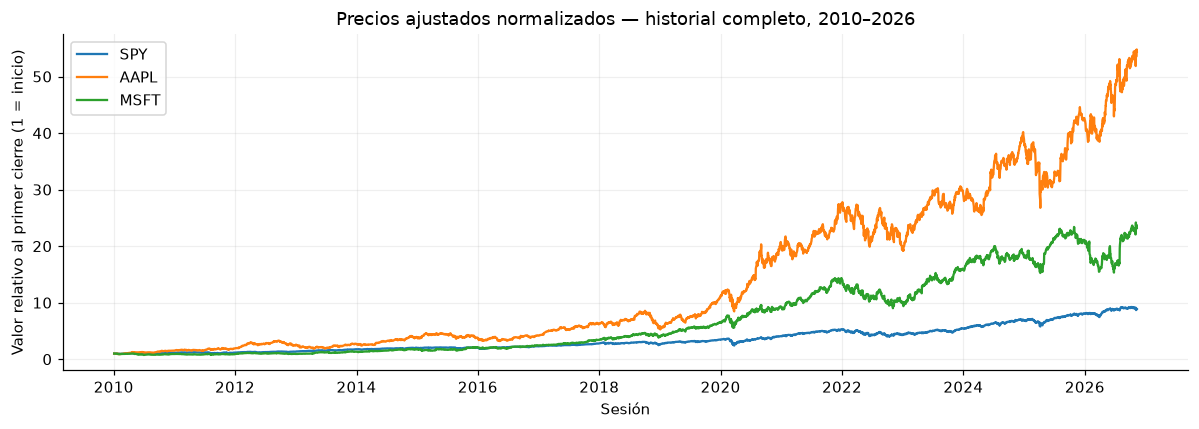

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
for ticker, frame in prices.items():
    ax.plot(frame.index, frame.Close / frame.Close.iloc[0], label=ticker)
ax.set(title='Precios ajustados normalizados — historial completo, 2010–2026',
       xlabel='Sesión', ylabel='Valor relativo al primer cierre (1 = inicio)')
ax.legend()
fig.tight_layout()
plt.show()

## Resultados

### Entrenamiento y auditoría

Esta celda ejecuta las búsquedas pequeñas definidas en `src/models.py`; puede tardar varios minutos. Nunca se selecciona por rendimiento del backtest ni por el test final. Se guardan métricas, parámetros, particiones, predicciones individuales y auditorías en `data/processed/`.

In [4]:
evaluations: dict[str, EvaluationResult] = {}
backtest_tables = []
backtest_curves = {}
goals_rows = []
for ticker in TICKERS:
    print(f'{ticker}: iniciando validación temporal anidada...', flush=True)
    started = time.perf_counter()
    result = evaluate_ticker(datasets[ticker], holdout_size=HOLDOUT_SIZE)
    evaluations[ticker] = result
    dataset, frame = datasets[ticker], prices[ticker]

    expected_target = (frame.Close.shift(-1) > frame.Close).loc[dataset.index].astype(int)
    assert np.array_equal(expected_target.to_numpy(), dataset.target.to_numpy())
    assert np.array_equal((frame.Close.pct_change(fill_method=None).loc[dataset.index] > 0).astype(int), dataset.persistence)
    assert (pd.to_datetime(result.splits.train_label_end) < pd.to_datetime(result.splits.test_start)).all()
    assert np.isfinite(result.predictions.probability).all()
    assert result.predictions.probability.between(0, 1).all()
    for _, group in result.predictions.groupby(['stage', 'model', 'fold']):
        assert np.array_equal(dataset.loc[pd.DatetimeIndex(group.date), 'target'].to_numpy(), group.target.to_numpy())
    all_metrics = pd.concat([result.fold_metrics, result.final_metrics], ignore_index=True)
    assert np.allclose(all_metrics.loc[all_metrics.model == 'always_up', 'auc'], 0.5)
    result.audit.update({'feature_causality': feature_audits[ticker], 'target_alignment_passed': True,
                         'prediction_alignment_passed': True, 'constant_baseline_auc_passed': True,
                         'audit_status': 'completed_fixed_snapshot_checks',
                         'point_in_time_data_guarantee': False})
    if result.audit['audit_required']:
        result.audit['findings'] = [
            'Se revisaron prefijos, alteración del futuro, etiquetas, límites temporales y baseline constante.',
            'No se encontró leakage en estos controles; no se ajustaron parámetros a partir del test final.',
            'La alerta permanece visible y no certifica ausencia de todo sesgo ni datos point-in-time.'
        ]
    summary = result.summary.set_index('model').loc[result.selected_model]
    final = result.final_metrics.set_index('model').loc[result.selected_model]
    result.audit['low_walk_forward_accuracy'] = bool(summary.accuracy_mean < 0.48)
    goals_rows.append({'ticker': ticker, 'selected_model': result.selected_model,
                       'cv_accuracy': summary.accuracy_mean, 'cv_auc': summary.auc_mean,
                       'cv_delta_always_up_pp': 100 * summary.delta_accuracy_always_up,
                       'cv_delta_persistence_pp': 100 * summary.delta_accuracy_persistence,
                       'final_accuracy': final.accuracy, 'final_auc': final.auc,
                       'final_delta_always_up_pp': 100 * final.delta_accuracy_always_up,
                       'final_delta_persistence_pp': 100 * final.delta_accuracy_persistence,
                       'accuracy_goal_met': bool(summary.accuracy_mean >= 0.48),
                       'cv_auc_goal_met': bool(summary.auc_mean > 0.50),
                       'final_auc_above_chance': bool(final.auc > 0.50),
                       'high_accuracy_alerts': len(result.audit['accuracy_above_60'])})
    for name in ['fold_metrics', 'summary', 'final_metrics', 'confusion_totals', 'predictions', 'splits']:
        getattr(result, name).to_csv(PROCESSED / f'{ticker}_{name}.csv', index=False)
    (PROCESSED / f'{ticker}_parameters.json').write_text(json.dumps(result.parameters, indent=2), encoding='utf-8')
    (PROCESSED / f'{ticker}_audit.json').write_text(json.dumps(result.audit, indent=2, ensure_ascii=False), encoding='utf-8')
    for stage in ['walk_forward', 'final']:
        table, curves = compare_strategies(frame, result.predictions[result.predictions.stage == stage], FEE)
        table.insert(0, 'stage', stage)
        table.insert(0, 'ticker', ticker)
        backtest_tables.append(table)
        backtest_curves[ticker, stage] = curves
        for name, curve in curves.items():
            curve.curve.to_csv(PROCESSED / f'{ticker}_{stage}_{name}_equity.csv')
    print(f'{ticker}: seleccionado {result.selected_model}; {time.perf_counter() - started:.1f} s; auditoría completada.', flush=True)

goals = pd.DataFrame(goals_rows)
backtests = pd.concat(backtest_tables, ignore_index=True)
goals.to_csv(PROCESSED / 'goals.csv', index=False)
backtests.to_csv(PROCESSED / 'backtest_metrics.csv', index=False)
manifest = {'start_inclusive': START, 'end_exclusive': END, 'holdout_rows': HOLDOUT_SIZE,
            'outer_folds': 5, 'inner_folds': 3, 'gap': 1, 'seed': 42, 'fee_per_side': FEE,
            'versions': VERSIONS, 'raw_metadata': raw_metadata,
            'selected_models': {t: r.selected_model for t, r in evaluations.items()},
            'notebook_assertions_passed': True}
(PROCESSED / 'experiment_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
display(goals.round(4))

SPY: iniciando validación temporal anidada...


SPY: seleccionado logistic; 71.4 s; auditoría completada.


AAPL: iniciando validación temporal anidada...


AAPL: seleccionado random_forest; 84.7 s; auditoría completada.


MSFT: iniciando validación temporal anidada...


MSFT: seleccionado xgboost; 74.5 s; auditoría completada.


,ticker,selected_model,cv_accuracy,cv_auc,cv_delta_always_up_pp,cv_delta_persistence_pp,final_accuracy,final_auc,final_delta_always_up_pp,final_delta_persistence_pp,accuracy_goal_met,cv_auc_goal_met,final_auc_above_chance,high_accuracy_alerts
0,SPY,logistic,0.5248,0.5083,-2.6384,3.6156,0.5337,0.4287,-1.5873,2.3810,True,True,False,0
1,AAPL,random_forest,0.5107,0.5084,-1.5309,1.8893,0.5377,0.5133,0.3968,4.3651,True,True,True,0
2,MSFT,xgboost,0.5094,0.5098,-1.9218,2.7036,0.5337,0.5237,1.1905,4.7619,True,True,True,0


### Particiones temporales y trazabilidad

El gráfico utiliza SPY como ejemplo. La tabla conserva los límites externos de los tres tickers; los límites internos completos se exportan también. Las zonas sin evaluar al comienzo no se rellenan con predicciones de entrenamiento.

,ticker,stage,fold,train_start,train_end,train_label_end,test_start,test_end,train_rows,test_rows
0,SPY,walk_forward,1,2010-03-16,2012-08-17,2012-08-20,2012-08-21,2015-01-30,614,614
1,SPY,walk_forward,2,2010-03-16,2015-01-29,2015-01-30,2015-02-02,2017-07-10,1228,614
2,SPY,walk_forward,3,2010-03-16,2017-07-07,2017-07-10,2017-07-11,2019-12-16,1842,614
3,SPY,walk_forward,4,2010-03-16,2019-12-13,2019-12-16,2019-12-17,2022-05-24,2456,614
4,SPY,walk_forward,5,2010-03-16,2022-05-23,2022-05-24,2022-05-25,2024-11-01,3070,614
5,SPY,final,0,2010-03-16,2024-11-01,2024-11-04,2024-11-05,2026-11-09,3685,504
6,AAPL,walk_forward,1,2010-03-16,2012-08-17,2012-08-20,2012-08-21,2015-01-30,614,614
7,AAPL,walk_forward,2,2010-03-16,2015-01-29,2015-01-30,2015-02-02,2017-07-10,1228,614
8,AAPL,walk_forward,3,2010-03-16,2017-07-07,2017-07-10,2017-07-11,2019-12-16,1842,614
9,AAPL,walk_forward,4,2010-03-16,2019-12-13,2019-12-16,2019-12-17,2022-05-24,2456,614


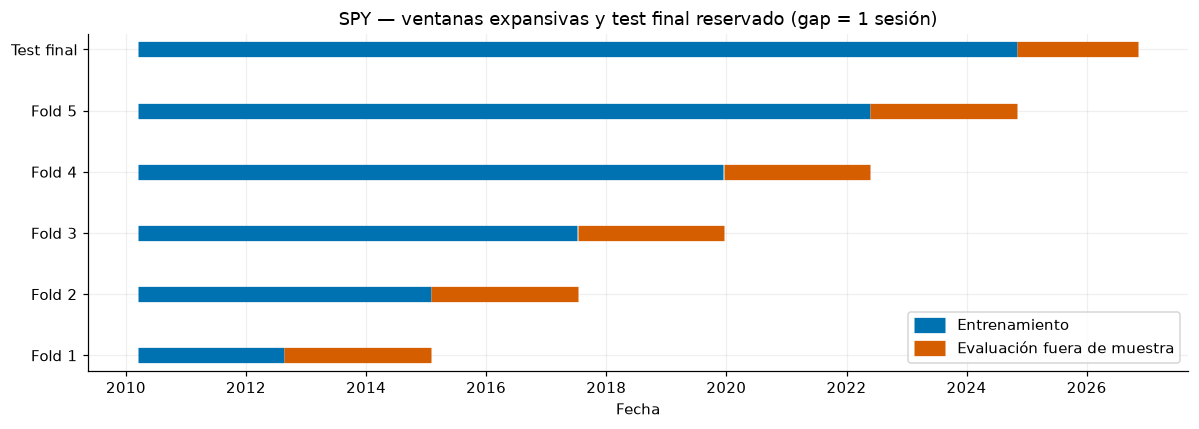

In [5]:
outer_tables = []
for ticker, result in evaluations.items():
    subset = result.splits[result.splits.level == 'outer'].copy()
    subset.insert(0, 'ticker', ticker)
    outer_tables.append(subset)
display(pd.concat(outer_tables, ignore_index=True).drop(columns=['level', 'inner_fold']))
split = evaluations['SPY'].splits.query("level == 'outer'")
fig, ax = plt.subplots(figsize=(11, 4))
for i, row in enumerate(split.itertuples()):
    ax.plot(pd.to_datetime([row.train_start, row.train_end]), [i, i], lw=10,
            color='#0072B2', label='Entrenamiento' if i == 0 else None, solid_capstyle='butt')
    ax.plot(pd.to_datetime([row.test_start, row.test_end]), [i, i], lw=10,
            color='#D55E00', label='Evaluación fuera de muestra' if i == 0 else None, solid_capstyle='butt')
ax.set_yticks(range(len(split)), [f'Fold {r.fold}' if r.stage == 'walk_forward' else 'Test final' for r in split.itertuples()])
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set(title='SPY — ventanas expansivas y test final reservado (gap = 1 sesión)', xlabel='Fecha')
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

### Walk-forward: todos los modelos y ambos baselines

Accuracy, precision y recall usan el umbral fijo 0,50. Las diferencias de accuracy se expresan en **puntos porcentuales**. La desviación estándar entre cinco folds describe variación temporal; no es un intervalo de confianza. Las matrices agregadas suman conteos; las medias de métricas son medias simples entre folds.

In [6]:
for ticker, result in evaluations.items():
    display(Markdown(f'#### {ticker}: métricas por fold'))
    display(result.fold_metrics.drop(columns='stage').round(4))
    summary = result.summary.copy()
    for column in ['delta_accuracy_always_up', 'delta_accuracy_persistence']:
        summary[column + '_pp'] = summary.pop(column) * 100
    display(Markdown('Promedios y desviaciones estándar'))
    display(summary.round(4))

#### SPY: métricas por fold

,fold,model,n,accuracy,auc,precision,recall,tn,fp,fn,tp
0,1,logistic,614,0.5293,0.5274,0.5892,0.5909,117,145,144,208
1,1,random_forest,614,0.5472,0.4491,0.5649,0.9148,14,248,30,322
2,1,xgboost,614,0.4951,0.4732,0.5550,0.6023,92,170,140,212
3,1,always_up,614,0.5733,0.5000,0.5733,1.0000,0,262,0,352
4,1,persistence,614,0.4902,0.4793,0.5556,0.5540,106,156,157,195
5,2,logistic,614,0.5114,0.5006,0.5204,0.7233,84,212,88,230
6,2,random_forest,614,0.5098,0.5150,0.5148,0.9277,18,278,23,295
7,2,xgboost,614,0.5293,0.5115,0.5373,0.6572,116,180,109,209
8,2,always_up,614,0.5179,0.5000,0.5179,1.0000,0,296,0,318
9,2,persistence,614,0.4414,0.4406,0.4608,0.4623,124,172,171,147


Promedios y desviaciones estándar

,model,accuracy_mean,accuracy_std,auc_mean,auc_std,precision_mean,precision_std,recall_mean,recall_std,delta_accuracy_always_up_pp,delta_accuracy_persistence_pp
0,always_up,0.5511,0.0241,0.5000,0.0000,0.5511,0.0241,1.0000,0.0000,0.0000,6.2541
1,logistic,0.5248,0.0151,0.5083,0.0136,0.5578,0.0285,0.7065,0.1623,-2.6384,3.6156
2,persistence,0.4886,0.0335,0.4824,0.0318,0.5348,0.0461,0.5348,0.0450,-6.2541,0.0000
3,random_forest,0.5384,0.0211,0.4995,0.0288,0.5539,0.0287,0.8658,0.0831,-1.2704,4.9837
4,xgboost,0.5179,0.0204,0.4954,0.0217,0.5559,0.0243,0.6552,0.1269,-3.3225,2.9316


#### AAPL: métricas por fold

,fold,model,n,accuracy,auc,precision,recall,tn,fp,fn,tp
0,1,logistic,614,0.4870,0.5127,0.5000,0.7524,62,237,78,237
1,1,random_forest,614,0.5309,0.5315,0.5316,0.7206,99,200,88,227
2,1,xgboost,614,0.5033,0.5048,0.5140,0.5810,126,173,132,183
3,1,always_up,614,0.5130,0.5000,0.5130,1.0000,0,299,0,315
4,1,persistence,614,0.4902,0.4899,0.5032,0.5016,143,156,157,158
5,2,logistic,614,0.4723,0.4772,0.4899,0.7707,48,252,72,242
6,2,random_forest,614,0.4837,0.4913,0.4967,0.7229,70,230,87,227
7,2,xgboost,614,0.4674,0.4675,0.4829,0.5860,103,197,130,184
8,2,always_up,614,0.5114,0.5000,0.5114,1.0000,0,300,0,314
9,2,persistence,614,0.4723,0.4720,0.4841,0.4841,138,162,162,152


... (2 outputs left out)

#### MSFT: métricas por fold

,fold,model,n,accuracy,auc,precision,recall,tn,fp,fn,tp
0,1,logistic,614,0.4902,0.5000,0.4927,0.4369,166,139,174,135
1,1,random_forest,614,0.4707,0.4681,0.4619,0.3139,192,113,212,97
2,1,xgboost,614,0.4756,0.4793,0.4741,0.3851,173,132,190,119
3,1,always_up,614,0.5033,0.5000,0.5033,1.0000,0,305,0,309
4,1,persistence,614,0.4919,0.4918,0.4951,0.4951,149,156,156,153
5,2,logistic,614,0.5098,0.5136,0.5336,0.3766,194,104,197,119
6,2,random_forest,614,0.5179,0.5223,0.5340,0.4968,161,137,159,157
7,2,xgboost,614,0.5407,0.5304,0.5644,0.4715,183,115,167,149
8,2,always_up,614,0.5147,0.5000,0.5147,1.0000,0,298,0,316
9,2,persistence,614,0.4723,0.4719,0.4873,0.4873,136,162,162,154


Promedios y desviaciones estándar

,model,accuracy_mean,accuracy_std,auc_mean,auc_std,precision_mean,precision_std,recall_mean,recall_std,delta_accuracy_always_up_pp,delta_accuracy_persistence_pp
0,always_up,0.5287,0.0265,0.5000,0.0000,0.5287,0.0265,1.0000,0.0000,0.0000,4.6254
1,logistic,0.5059,0.0105,0.5069,0.0318,0.5433,0.0580,0.5156,0.1800,-2.2801,2.3453
2,persistence,0.4824,0.0268,0.4794,0.0285,0.5098,0.0279,0.5102,0.0291,-4.6254,0.0000
3,random_forest,0.5075,0.0237,0.5037,0.0223,0.5294,0.0446,0.5596,0.2056,-2.1173,2.5081
4,xgboost,0.5094,0.0232,0.5098,0.0221,0.5385,0.0453,0.5111,0.1109,-1.9218,2.7036


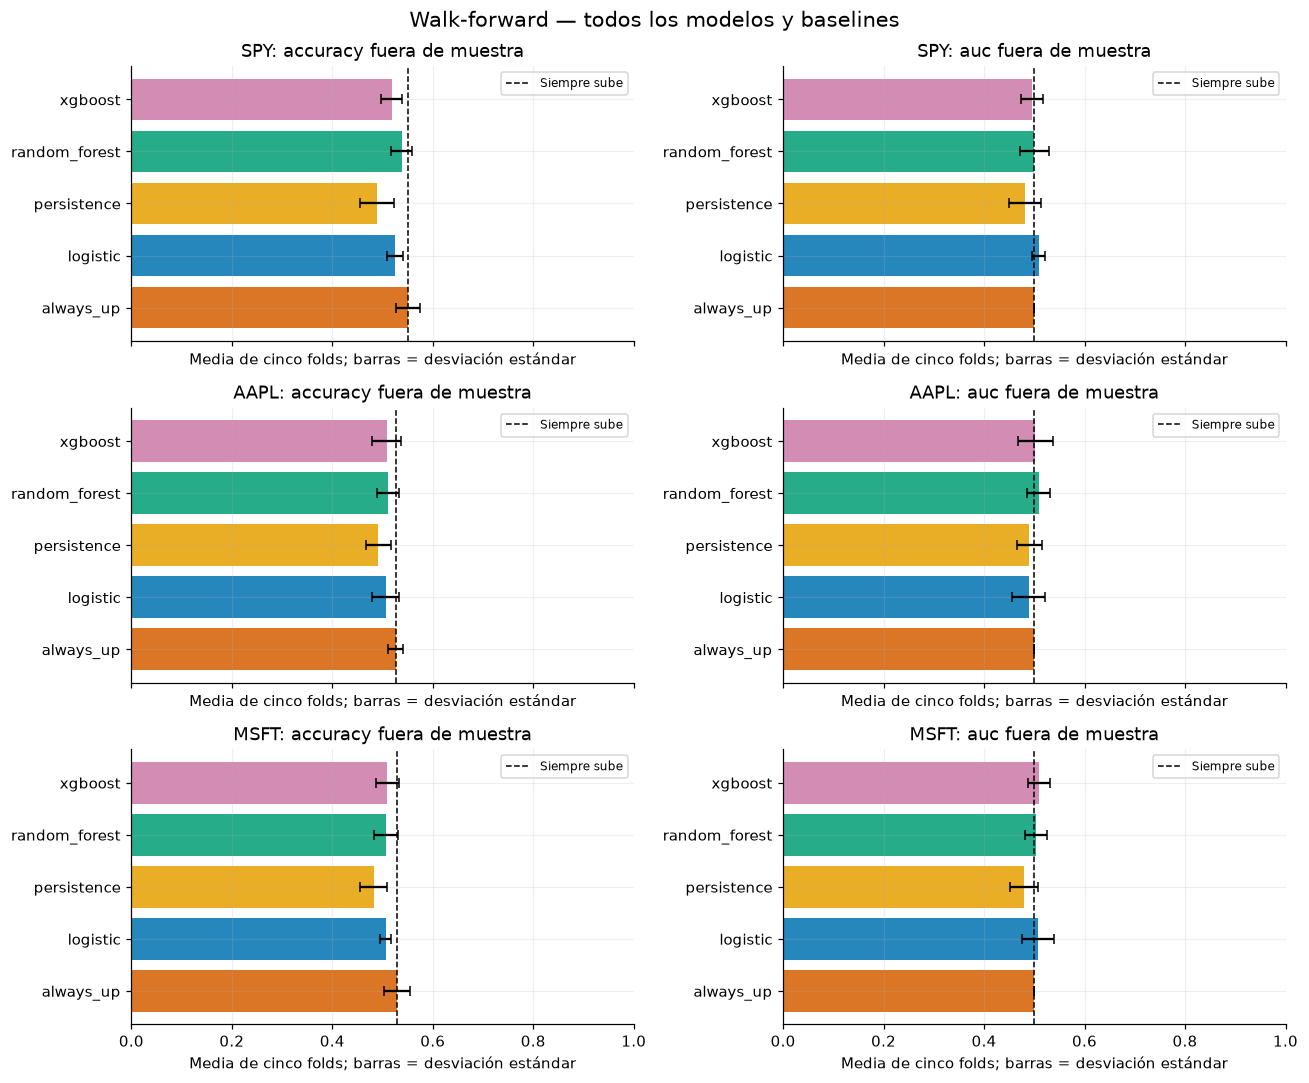

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for row, ticker in enumerate(TICKERS):
    table = evaluations[ticker].summary
    for column, metric in enumerate(['accuracy', 'auc']):
        ax = axes[row, column]
        ax.barh(table.model, table[f'{metric}_mean'], xerr=table[f'{metric}_std'],
                color=[COLORS[name] for name in table.model], alpha=0.85, capsize=3)
        baseline = table.set_index('model').loc['always_up', f'{metric}_mean']
        ax.axvline(baseline, color='black', ls='--', lw=1, label='Siempre sube')
        ax.set(title=f'{ticker}: {metric} fuera de muestra', xlim=(0, 1))
        ax.set_xlabel('Media de cinco folds; barras = desviación estándar')
        ax.legend(fontsize=8)
fig.suptitle('Walk-forward — todos los modelos y baselines', fontsize=14)
fig.tight_layout()
plt.show()

### Test final: modelo elegido previamente y baselines

Cada ticker tiene un único modelo seleccionado antes de consultar este período. Una mejora en desarrollo puede desaparecer aquí. No se prueban las otras familias sobre el test final para elegir retrospectivamente la mejor.

In [8]:
for ticker, result in evaluations.items():
    display(Markdown(f'#### {ticker}: test final; modelo elegido = {result.selected_model}'))
    table = result.final_metrics.drop(columns=['stage', 'fold']).copy()
    for column in ['delta_accuracy_always_up', 'delta_accuracy_persistence']:
        table[column + '_pp'] = table.pop(column) * 100
    display(table.round(4))
    display(Markdown('Matrices agregadas: desarrollo fuera de muestra y test final'))
    display(result.confusion_totals)
    display(Markdown('Hiperparámetros seleccionados exclusivamente en validación interna'))
    display(pd.DataFrame(result.parameters))

#### SPY: test final; modelo elegido = logistic

,model,n,accuracy,auc,precision,recall,tn,fp,fn,tp,delta_accuracy_always_up_pp,delta_accuracy_persistence_pp
25,logistic,504,0.5337,0.4287,0.5438,0.9422,8,219,16,261,-1.5873,2.3810
26,always_up,504,0.5496,0.5000,0.5496,1.0000,0,227,0,277,0.0000,3.9683
27,persistence,504,0.5099,0.5049,0.5540,0.5560,103,124,123,154,-3.9683,0.0000


Matrices agregadas: desarrollo fuera de muestra y test final

,stage,model,tn,fp,fn,tp
0,final,always_up,0,227,0,277
1,final,logistic,8,219,16,261
2,final,persistence,103,124,123,154
3,walk_forward,always_up,0,1378,0,1692
4,walk_forward,logistic,422,956,503,1189
5,walk_forward,persistence,593,785,785,907
6,walk_forward,random_forest,191,1187,230,1462
7,walk_forward,xgboost,486,892,588,1104


Hiperparámetros seleccionados exclusivamente en validación interna

,stage,fold,model,parameters,inner_auc
0,walk_forward,1,logistic,{'model__C': 10.0},0.498094
1,walk_forward,1,random_forest,"{'model__max_depth': 3, 'model__min_samples_leaf': 10}",0.525424
2,walk_forward,1,xgboost,"{'model__learning_rate': 0.1, 'model__max_depth': 3}",0.555017
3,walk_forward,2,logistic,{'model__C': 10.0},0.524181
4,walk_forward,2,random_forest,"{'model__max_depth': 6, 'model__min_samples_leaf': 10}",0.485376
5,walk_forward,2,xgboost,"{'model__learning_rate': 0.1, 'model__max_depth': 3}",0.516837
6,walk_forward,3,logistic,{'model__C': 10.0},0.523269
7,walk_forward,3,random_forest,"{'model__max_depth': 3, 'model__min_samples_leaf': 10}",0.498366
8,walk_forward,3,xgboost,"{'model__learning_rate': 0.1, 'model__max_depth': 2}",0.498425
9,walk_forward,4,logistic,{'model__C': 10.0},0.508773


... (8 outputs left out)

Matrices agregadas: desarrollo fuera de muestra y test final

,stage,model,tn,fp,fn,tp
0,final,always_up,0,241,0,263
1,final,persistence,111,130,129,134
2,final,xgboost,79,162,73,190
3,walk_forward,always_up,0,1447,0,1623
4,walk_forward,logistic,719,728,789,834
5,walk_forward,persistence,652,795,794,829
6,walk_forward,random_forest,649,798,714,909
7,walk_forward,xgboost,734,713,793,830


Hiperparámetros seleccionados exclusivamente en validación interna

,stage,fold,model,parameters,inner_auc
0,walk_forward,1,logistic,{'model__C': 0.1},0.486458
1,walk_forward,1,random_forest,"{'model__max_depth': 6, 'model__min_samples_leaf': 10}",0.464037
2,walk_forward,1,xgboost,"{'model__learning_rate': 0.1, 'model__max_depth': 3}",0.495702
3,walk_forward,2,logistic,{'model__C': 10.0},0.498855
4,walk_forward,2,random_forest,"{'model__max_depth': 6, 'model__min_samples_leaf': 30}",0.489954
5,walk_forward,2,xgboost,"{'model__learning_rate': 0.1, 'model__max_depth': 3}",0.497076
6,walk_forward,3,logistic,{'model__C': 10.0},0.481489
7,walk_forward,3,random_forest,"{'model__max_depth': 6, 'model__min_samples_leaf': 10}",0.493214
8,walk_forward,3,xgboost,"{'model__learning_rate': 0.1, 'model__max_depth': 3}",0.498721
9,walk_forward,4,logistic,{'model__C': 0.1},0.523634


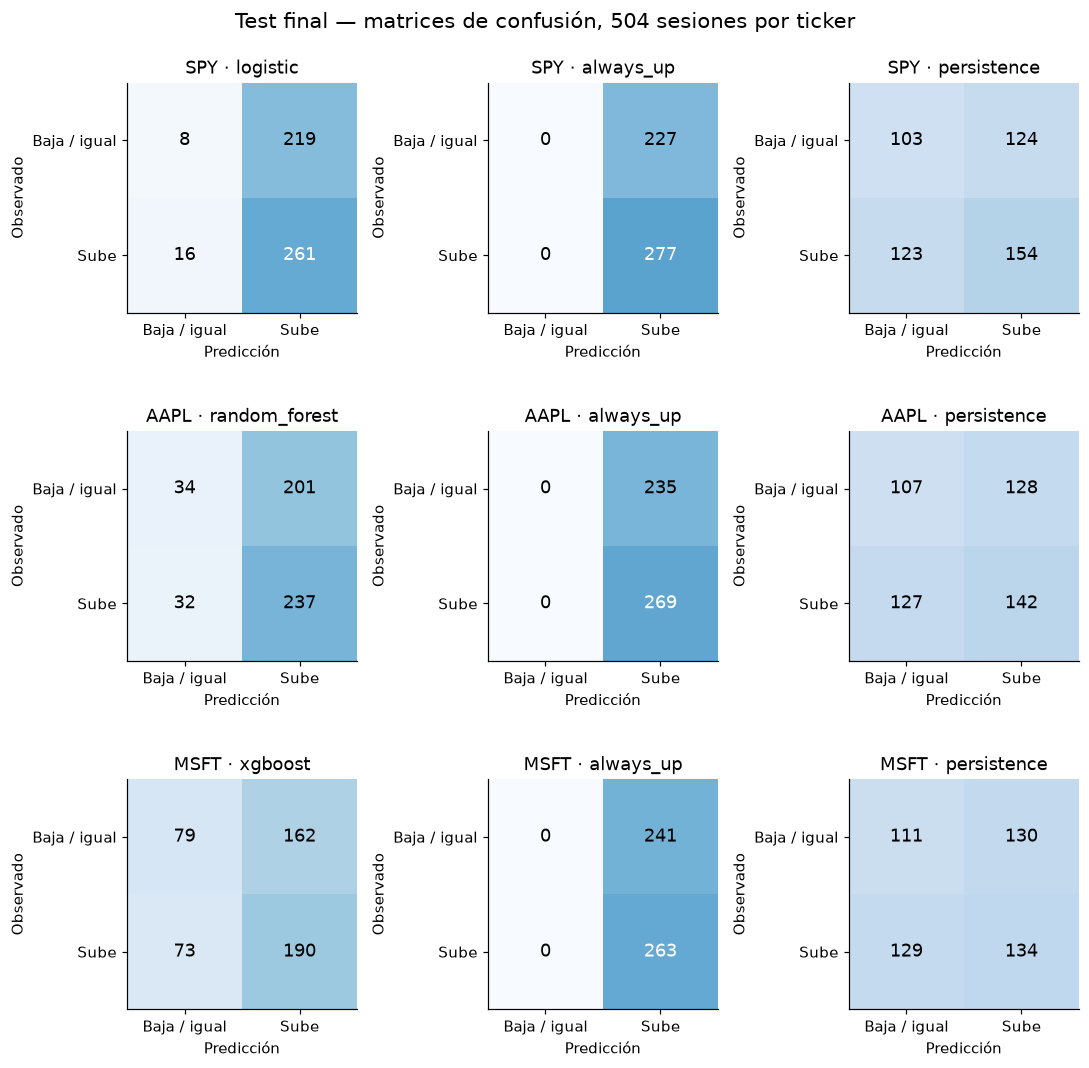

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row, ticker in enumerate(TICKERS):
    result = evaluations[ticker]
    table = result.final_metrics.set_index('model')
    for column, model in enumerate([result.selected_model, 'always_up', 'persistence']):
        record = table.loc[model]
        matrix = np.array([[record.tn, record.fp], [record.fn, record.tp]], dtype=int)
        ax = axes[row, column]
        ax.imshow(matrix, cmap='Blues', vmin=0, vmax=HOLDOUT_SIZE)
        for (i, j), value in np.ndenumerate(matrix):
            ax.text(j, i, str(value), ha='center', va='center', fontsize=12,
                    color='white' if value > HOLDOUT_SIZE / 2 else 'black')
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Baja / igual', 'Sube'],
               yticklabels=['Baja / igual', 'Sube'], xlabel='Predicción', ylabel='Observado',
               title=f'{ticker} · {model}')
        ax.grid(False)
fig.suptitle('Test final — matrices de confusión, 504 sesiones por ticker', fontsize=14)
fig.tight_layout()
plt.show()

### Backtest neto: desarrollo y test final separados

Todas las estrategias de cada comparación usan las mismas fechas. La señal final sin dos aperturas futuras se recorta; la tabla declara cuántas señales se excluyen. `always_up` y `buy_hold` son económicamente idénticos bajo estas reglas; ambas curvas se conservan para poder verificarlo. La curva buy and hold se dibuja discontinua.

Los costos incluyen comisiones, pero **no** slippage, spread, impacto, impuestos ni restricciones operativas. Una AUC ligeramente superior a 0,50 no implica rentabilidad, y este backtest no representa ejecución garantizada.

#### walk_forward: retorno, riesgo y costos

,ticker,strategy,cumulative_return,sharpe,max_drawdown,operations,periods,trimmed_signals,total_commission_initial_capital,exposure
0,SPY,logistic,1.4985,0.6008,-0.3206,516,3070,0,0.7249,0.6987
1,SPY,random_forest,2.2361,0.7147,-0.3205,376,3070,0,0.6803,0.8629
2,SPY,xgboost,0.5248,0.3222,-0.4054,1008,3070,0,1.0564,0.6502
3,SPY,always_up,4.0323,0.9128,-0.3205,2,3070,0,0.0060,1.0000
4,SPY,persistence,-0.5263,-0.5340,-0.5598,1570,3070,0,1.0461,0.5511
5,SPY,buy_hold,4.0323,0.9128,-0.3205,2,3070,0,0.0060,1.0000
10,AAPL,logistic,2.4878,0.5545,-0.4864,542,3070,0,0.9091,0.7326
11,AAPL,random_forest,6.0810,0.7486,-0.4038,550,3070,0,1.3324,0.7990
12,AAPL,xgboost,1.9075,0.4880,-0.2656,880,3070,0,1.4560,0.6739
13,AAPL,always_up,10.1673,0.8239,-0.4419,2,3070,0,0.0122,1.0000


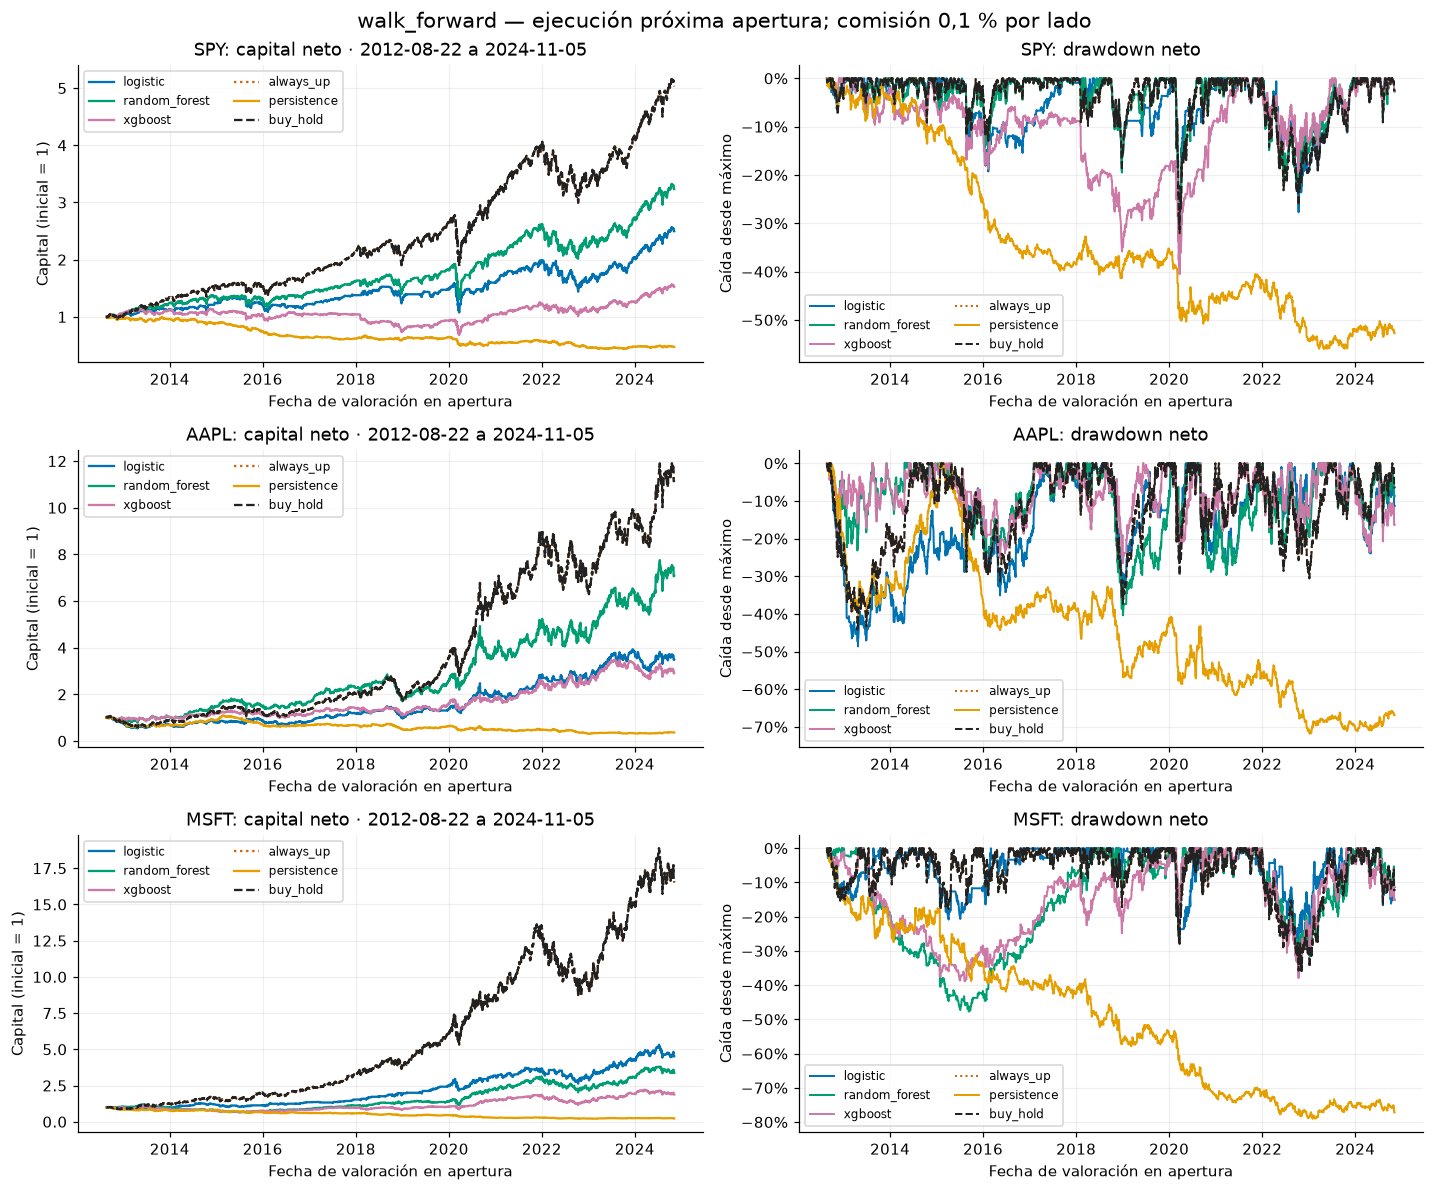

#### final: retorno, riesgo y costos

,ticker,strategy,cumulative_return,sharpe,max_drawdown,operations,periods,trimmed_signals,total_commission_initial_capital,exposure
6,SPY,logistic,0.2546,0.8230,-0.1823,34,503,1,0.0357,0.9543
7,SPY,always_up,0.2961,0.8510,-0.1977,2,503,1,0.0023,1.0000
8,SPY,persistence,-0.2783,-1.4738,-0.3029,248,503,1,0.2070,0.5507
9,SPY,buy_hold,0.2961,0.8510,-0.1977,2,503,1,0.0023,1.0000
16,AAPL,random_forest,0.4717,0.8066,-0.3305,74,503,1,0.0841,0.8688
17,AAPL,always_up,0.5883,0.9102,-0.3333,2,503,1,0.0026,1.0000
18,AAPL,persistence,-0.1161,-0.2567,-0.2935,254,503,1,0.2390,0.5348
19,AAPL,buy_hold,0.5883,0.9102,-0.3333,2,503,1,0.0026,1.0000
26,MSFT,xgboost,0.3462,0.7239,-0.2739,138,503,1,0.1431,0.6978
27,MSFT,always_up,0.3347,0.6302,-0.3516,2,503,1,0.0023,1.0000


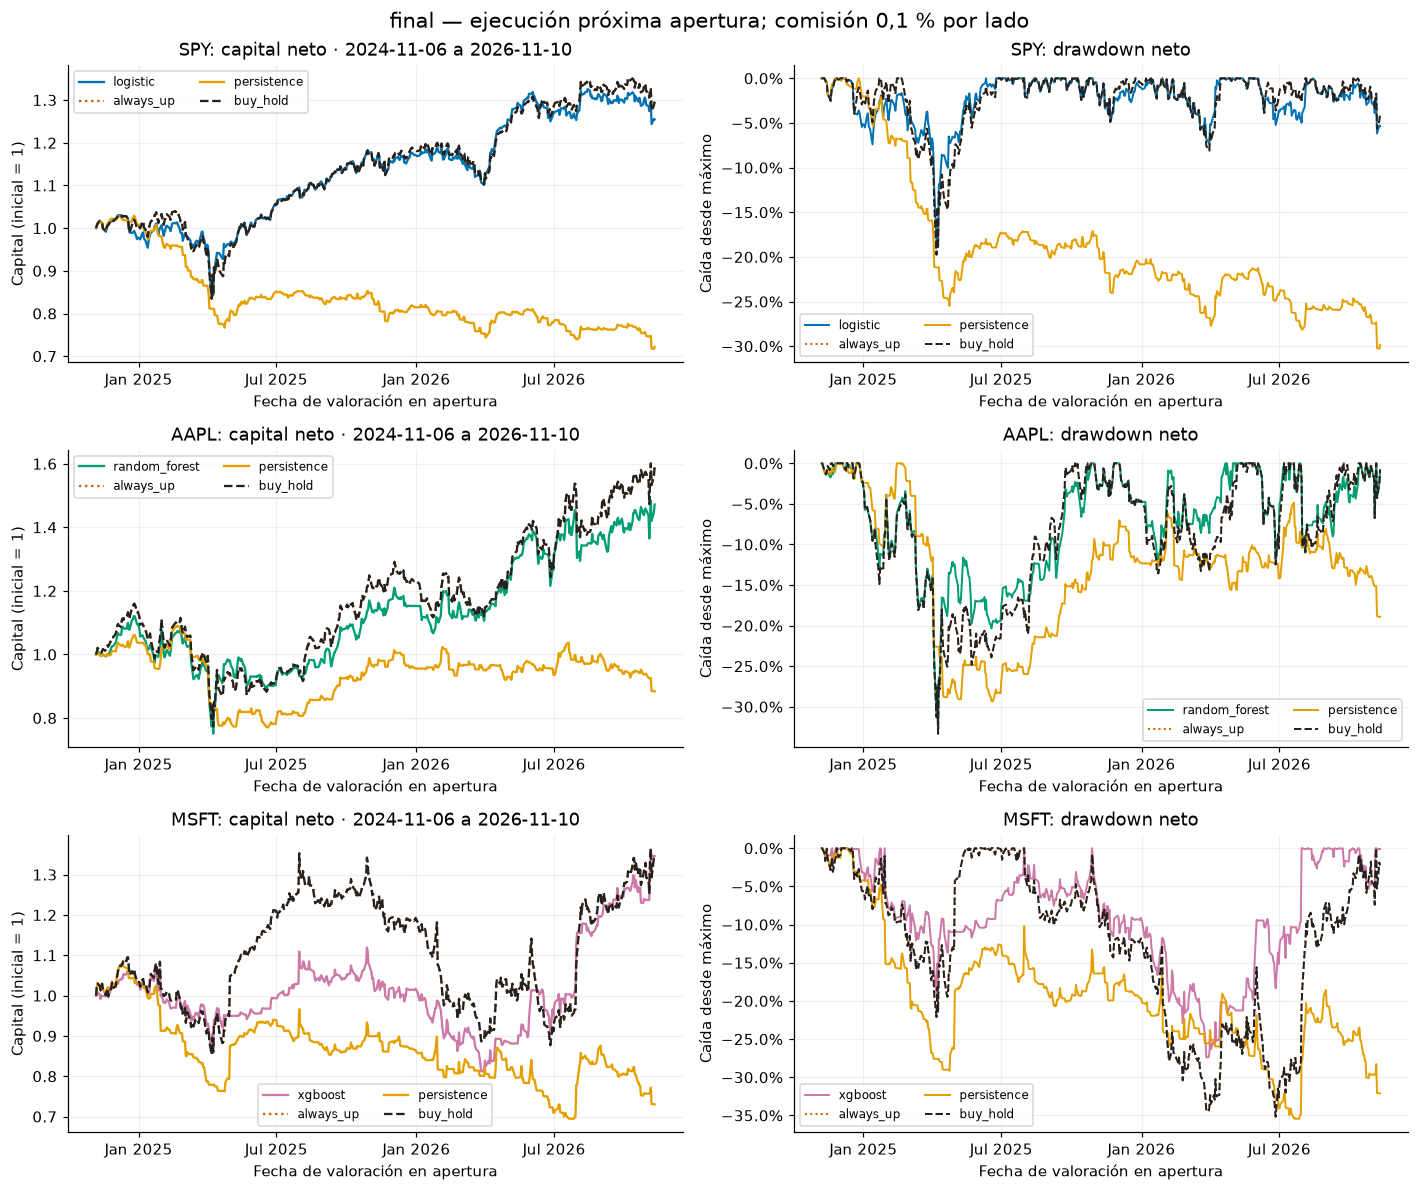

In [10]:
for stage in ['walk_forward', 'final']:
    display(Markdown(f'#### {stage}: retorno, riesgo y costos'))
    display(backtests[backtests.stage == stage].drop(columns='stage').round(4))
    fig, axes = plt.subplots(3, 2, figsize=(13, 11))
    for row, ticker in enumerate(TICKERS):
        curves = backtest_curves[ticker, stage]
        for name, result in curves.items():
            curve = result.curve
            style = '--' if name == 'buy_hold' else ':' if name == 'always_up' else '-'
            start = pd.Series([1.0], index=pd.DatetimeIndex([curve.execution_date.iloc[0]]))
            equity = pd.concat([start, curve.equity])
            axes[row, 0].plot(equity.index, equity, label=name, color=COLORS[name], ls=style, lw=1.5)
            axes[row, 1].plot(curve.index, curve.drawdown, label=name, color=COLORS[name], ls=style, lw=1.3)
        first = next(iter(curves.values())).curve
        period = f'{first.execution_date.iloc[0]:%Y-%m-%d} a {first.index[-1]:%Y-%m-%d}'
        axes[row, 0].set(title=f'{ticker}: capital neto · {period}', ylabel='Capital (inicial = 1)')
        axes[row, 1].set(title=f'{ticker}: drawdown neto', ylabel='Caída desde máximo')
        axes[row, 1].yaxis.set_major_formatter(PercentFormatter(1))
        for ax in axes[row]:
            ax.set_xlabel('Fecha de valoración en apertura')
            ax.legend(fontsize=8, ncol=2)
            locator = mdates.YearLocator(2) if stage == 'walk_forward' else mdates.MonthLocator(interval=6)
            ax.xaxis.set_major_locator(locator)
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y' if stage == 'walk_forward' else '%b %Y'))
    fig.suptitle(f'{stage} — ejecución próxima apertura; comisión 0,1 % por lado', fontsize=14)
    fig.tight_layout()
    plt.show()

### Auditoría y cumplimiento de metas

Se conservan todas las alertas >60 %, incluso si provienen de un baseline o de un solo fold. Los controles comprueban causalidad de features, alineación del target y predicciones, separación temporal y AUC del baseline constante. No constituyen una certificación de datos point-in-time.

In [11]:
display(goals.round(4))
for ticker, result in evaluations.items():
    display(Markdown(f'**{ticker}:** {result.audit["audit_status"]}; '
                     f'alertas >60 %: {len(result.audit["accuracy_above_60"])}; '
                     f'accuracy media <48 %: {result.audit["low_walk_forward_accuracy"]}.'))
    if result.audit['accuracy_above_60']:
        display(pd.DataFrame(result.audit['accuracy_above_60']).round(4))
    if result.audit['low_walk_forward_accuracy']:
        display(Markdown('Los controles técnicos pasaron; se conserva el incumplimiento como resultado negativo, sin asumir automáticamente un bug.'))

,ticker,selected_model,cv_accuracy,cv_auc,cv_delta_always_up_pp,cv_delta_persistence_pp,final_accuracy,final_auc,final_delta_always_up_pp,final_delta_persistence_pp,accuracy_goal_met,cv_auc_goal_met,final_auc_above_chance,high_accuracy_alerts
0,SPY,logistic,0.5248,0.5083,-2.6384,3.6156,0.5337,0.4287,-1.5873,2.3810,True,True,False,0
1,AAPL,random_forest,0.5107,0.5084,-1.5309,1.8893,0.5377,0.5133,0.3968,4.3651,True,True,True,0
2,MSFT,xgboost,0.5094,0.5098,-1.9218,2.7036,0.5337,0.5237,1.1905,4.7619,True,True,True,0


**SPY:** completed_fixed_snapshot_checks; alertas >60 %: 0; accuracy media <48 %: False.

**AAPL:** completed_fixed_snapshot_checks; alertas >60 %: 0; accuracy media <48 %: False.

**MSFT:** completed_fixed_snapshot_checks; alertas >60 %: 0; accuracy media <48 %: False.

## Conclusiones y limitaciones

La comparación relevante es fuera de muestra y frente a ambos baselines. Las diferencias en puntos porcentuales se muestran aunque sean negativas. El test final está separado del desarrollo; repetir este notebook con la misma configuración reproduce el experimento, pero modificar la configuración después de ver el test comprometería su independencia.

Limitaciones: ajustes y revisiones retrospectivas de Yahoo; instantánea sin garantía point-in-time; selección de solo tres activos actualmente conocidos; dependencia serial, cambios de régimen y tamaños de muestra limitados; selección entre varias familias que puede optimizar desarrollo; ausencia de intervalos de confianza y pruebas de significación; falta de slippage, spread, impacto e impuestos; retorno operado distinto del target; sin rendimiento de efectivo. La desviación entre folds no equivale a incertidumbre inferencial. No se concluye una ventaja estadísticamente demostrada ni operabilidad real.

La reproducción exacta requiere conservar los CSV y hashes de esta ejecución. Una descarga posterior puede revisar el historial. No se sustituyen datos reales por datos sintéticos: estos últimos se utilizan solamente en `tests/`.

In [12]:
for row in goals.itertuples():
    final_table = backtests[(backtests.ticker == row.ticker) & (backtests.stage == 'final')].set_index('strategy')
    net = final_table.loc[row.selected_model, 'cumulative_return']
    hold = final_table.loc['buy_hold', 'cumulative_return']
    display(Markdown(
        f'**{row.ticker} — {row.selected_model}:** AUC walk-forward {row.cv_auc:.4f}; '
        f'AUC final {row.final_auc:.4f}; diferencia final de accuracy frente a siempre sube '
        f'{row.final_delta_always_up_pp:+.2f} pp y frente a persistencia {row.final_delta_persistence_pp:+.2f} pp. '
        f'Retorno neto final {net:.2%}, frente a buy and hold {hold:.2%}. '
        f'Estos valores describen esta muestra y no garantizan una ventaja futura.'
    ))
print('Ejecución completa. CSV, parámetros, auditorías y hashes disponibles en data/processed/.')

**SPY — logistic:** AUC walk-forward 0.5083; AUC final 0.4287; diferencia final de accuracy frente a siempre sube -1.59 pp y frente a persistencia +2.38 pp. Retorno neto final 25.46%, frente a buy and hold 29.61%. Estos valores describen esta muestra y no garantizan una ventaja futura.

**AAPL — random_forest:** AUC walk-forward 0.5084; AUC final 0.5133; diferencia final de accuracy frente a siempre sube +0.40 pp y frente a persistencia +4.37 pp. Retorno neto final 47.17%, frente a buy and hold 58.83%. Estos valores describen esta muestra y no garantizan una ventaja futura.

**MSFT — xgboost:** AUC walk-forward 0.5098; AUC final 0.5237; diferencia final de accuracy frente a siempre sube +1.19 pp y frente a persistencia +4.76 pp. Retorno neto final 34.62%, frente a buy and hold 33.47%. Estos valores describen esta muestra y no garantizan una ventaja futura.

Ejecución completa. CSV, parámetros, auditorías y hashes disponibles en data/processed/.
